# Feature Selection and Evaluation — CUB-200-2011 Tabular Attributes (R2)

Are all 312 attributes useful? Following Lecture 4 and the lab sheets, this notebook ranks the attributes, builds
**progressively smaller feature sets**, and evaluates them with three course classifiers to see which size works best.
The feature sets are saved so the R3 model notebooks can use them for the lab's "Data set 1 / 2 / 3" experiments.

**Input:** `data/cub_features_A.csv` from [`dataPrep.ipynb`](dataPrep.ipynb) (run that first).
**Output:** `data/feature_sets.json` and figures in `documentation/figures/` (prefix `features_`).

**Protocol (same as the model notebooks):** official split; all ranking and evaluation use the **training set only**,
with stratified 5-fold CV. The test set is never used here, so feature selection cannot "peek" at it.

| Step | Section |
|---|---|
| Lab method: most correlated attributes per class (top 2 / 5 / 10) | 2 |
| Ranking against all 200 species (Cramér's V, information gain) | 3 |
| Redundancy check (high relevance + low redundancy) | 4 |
| Building the feature sets | 5 |
| Evaluating the feature sets (5-fold CV) | 6 |
| Saving the feature sets | 7 |

## 1. Setup

In [1]:
# --- GenAI disclosure (F20DL coursework spec, Section 8) ---
# This notebook was drafted with Claude (Anthropic) in a guided conversation, then reviewed,
# run and checked by Muhammad Faizal Haris bin Aidi. Main prompts used:
# 1. "deeply analyse everything ... then later im gonna need your help in finishing this"
# 2. "lets do R2 to the best we can fully following the requirements and course contents"
# 3. "trim it down ... fully following what the course teaches"
# 4. "basically we gonna use [Ryan's data prep] for this, but add whats needed/not available yet"

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
SPLIT = 'is_train'  # official split, same as the main model notebooks
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
FIGURES = ROOT / 'documentation' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
META_COLS = ['image_id', 'class_id', 'class_name', 'is_train', 'is_train_80']  # never used as features

# One consistent look for every figure
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'font.size': 9, 'legend.frameon': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'

def load_features(variant='A'):
    """Feature table written by dataPrep.ipynb (variant A = raw 0/1 attributes)."""
    path = DATA / f'cub_features_{variant}.csv'
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run notebooks/dataPrep.ipynb first')
    df = pd.read_csv(path).copy()   # .copy() keeps the 300+ columns in one memory block
    df['species'] = df.class_name.str.split('.', n=1).str[1].str.replace('_', ' ')
    return df.copy()

def save_figure(fig, name):
    fig.savefig(FIGURES / f'{name}.png')

import json
from scipy.stats import chi2_contingency

df = load_features('A')
ATTR = [c for c in df.columns if c not in META_COLS + ['species']]

train = df[df[SPLIT] == 1].reset_index(drop=True)
X = train[ATTR]                 # 312 binary attributes
y = train['class_id']           # 200 species
print(f"Training set: {X.shape[0]:,} images x {X.shape[1]} attributes, {y.nunique()} species")

Training set: 5,994 images x 312 attributes, 200 species


## 2. Lab method: most correlated attributes per class

As in the lab sheet and the Addendum *"On best correlated features/class"*: for each species we create a one-vs-rest
target (1 = this species, 0 = any other), compute the correlation of every attribute with it, and keep the top *k*
by **absolute** value. Both variables are binary, so Pearson's *r* here is the phi coefficient.

In [2]:
def per_class_correlations(X, y):
    # Returns a (species x attribute) table of |correlation| with the one-vs-rest target.
    Xc = (X - X.mean()) / X.std(ddof=0)                      # standardise once
    out = {}
    for cls in sorted(y.unique()):
        target = (y == cls).astype(float)
        t = (target - target.mean()) / target.std(ddof=0)
        out[cls] = (Xc.mul(t, axis=0)).mean().abs()          # Pearson r = mean of products of z-scores
    return pd.DataFrame(out).T


abs_corr = per_class_correlations(X, y)

per_class_sets = {}
for k in [2, 5, 10]:
    chosen = set()
    for cls, row in abs_corr.iterrows():
        chosen.update(row.nlargest(k).index)
    per_class_sets[f"per-class top {k}"] = [c for c in ATTR if c in chosen]   # keep original order

pd.DataFrame({
    "attributes picked (k x 200)": [k * 200 for k in [2, 5, 10]],
    "unique attributes":           [len(v) for v in per_class_sets.values()],
    "% of all 312":                [round(100 * len(v) / len(ATTR)) for v in per_class_sets.values()],
}, index=per_class_sets.keys())

,attributes picked (k x 200),unique attributes,% of all 312
per-class top 2,400,162,52
per-class top 5,1000,244,78
per-class top 10,2000,288,92


In [3]:
# Example: the most correlated attributes for three species
examples = {cls: df.loc[df["class_id"] == cls, "species"].iloc[0] for cls in [17, 73, 188]}
pd.concat({name: abs_corr.loc[cls].nlargest(3).round(3).reset_index(drop=False)
                     .set_axis(["attribute", "|r|"], axis=1)
           for cls, name in examples.items()}, axis=1)

Cardinal                           Blue Jay         \
                   attribute    |r|                   attribute    |r|   
0  has_under_tail_color::red  0.331  has_upperparts_color::blue  0.261   
1  has_upperparts_color::red  0.293        has_wing_color::blue  0.258   
2        has_back_color::red  0.292     has_primary_color::blue  0.245   

             Pileated Woodpecker         
                       attribute    |r|  
0           has_crown_color::red  0.278  
1  has_shape::tree-clinging-like  0.224  
2        has_forehead_color::red  0.178

**Finding:** the per-class top attributes make sense biologically (e.g. red colours for the Cardinal), but with
**200 classes** the method barely reduces the data: even top-2 per class keeps about half the attributes, and top-10
keeps over 90%. The lab example had 3 classes; with many classes the per-class picks overlap and add up.
So we also rank attributes against the **whole** target.

## 3. Ranking against the whole 200-species target

Lecture 4 says to choose the association measure from the data types. Here the feature is **categorical (binary)**
and the target is **categorical (200 species)**, so we use:

* **Cramér's V** (categorical vs categorical, range 0–1): based on the chi-squared test of each attribute against the species.
* **Information gain** (Lecture 4 lists it as a filter method; in scikit-learn it is called *mutual information*):
  how much knowing the attribute reduces uncertainty about the species. Used as a second opinion.

In [4]:
from sklearn.feature_selection import mutual_info_classif

def cramers_v(feature, target):
    table = pd.crosstab(feature, target)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


ranking = pd.DataFrame({
    "cramers_v": [cramers_v(X[c], y) for c in ATTR],
    "mutual_info": mutual_info_classif(X, y, discrete_features=True, random_state=RANDOM_STATE),
    "prevalence_%": (X.mean() * 100).round(2).values,
}, index=ATTR).sort_values("cramers_v", ascending=False)

ranking.head(10).round(3)

,cramers_v,mutual_info,prevalence_%
has_throat_color::yellow,0.830,0.244,11.24
has_underparts_color::yellow,0.808,0.277,14.95
has_breast_color::yellow,0.798,0.256,13.66
has_belly_color::yellow,0.794,0.261,14.15
has_crown_color::red,0.784,0.128,4.59
has_primary_color::yellow,0.780,0.257,14.60
has_forehead_color::yellow,0.752,0.182,8.71
has_crown_color::blue,0.752,0.136,5.52
has_forehead_color::red,0.747,0.111,4.00
has_breast_color::red,0.743,0.103,3.82


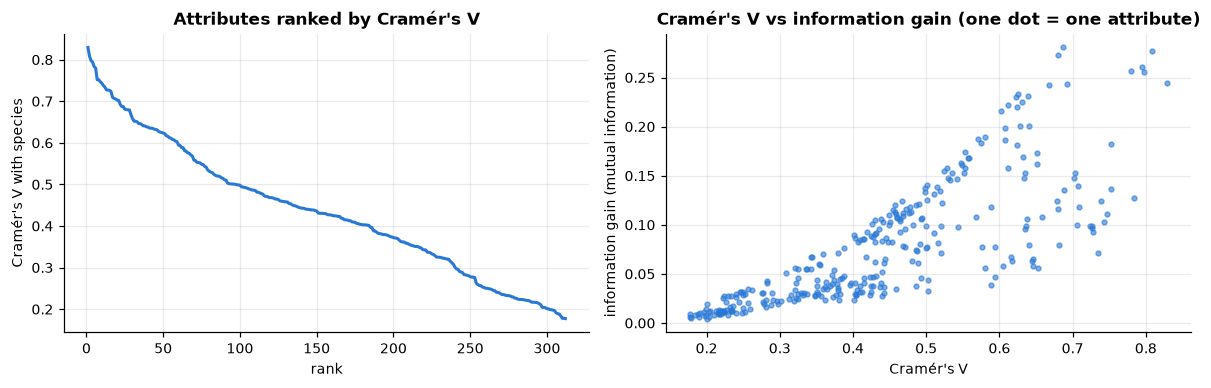

Least informative attributes:


,cramers_v,mutual_info,prevalence_%
has_upper_tail_color::purple,0.188,0.009,0.38
has_eye_color::pink,0.184,0.008,0.32
has_leg_color::green,0.178,0.005,0.17
has_under_tail_color::pink,0.178,0.009,0.43
has_eye_color::green,0.177,0.006,0.20


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(np.arange(1, len(ranking) + 1), ranking["cramers_v"].values, color=BLUE, lw=2)
axes[0].set(title="Attributes ranked by Cramér's V", xlabel="rank", ylabel="Cramér's V with species")

axes[1].scatter(ranking["cramers_v"], ranking["mutual_info"], s=10, color=BLUE, alpha=0.6)
axes[1].set(title="Cramér's V vs information gain (one dot = one attribute)",
            xlabel="Cramér's V", ylabel="information gain (mutual information)")
plt.tight_layout()
save_figure(fig, "features_ranking")
plt.show()

print("Least informative attributes:")
ranking.tail(5).round(3)

**Finding:** both measures largely agree, so the ranking is not an artefact of one measure. The most informative
attributes are distinctive colours and shapes; the least informative are attributes that are either extremely rare or
present in many species (e.g. black eyes).

## 4. Redundancy check

Lecture 4: the top-ranked features "may also be strongly correlated with each other". We want **high relevance + low
redundancy**. Simple filter: walk down the ranking and skip any attribute whose |phi| with an already-kept attribute
is above 0.8 (`eda.ipynb` §6 showed such pairs exist, e.g. belly colour vs underparts colour).

In [6]:
REDUNDANCY_THRESHOLD = 0.8
phi = X.corr().abs()

kept, dropped = [], []
for attr in ranking.index:
    too_similar = [k for k in kept if phi.loc[attr, k] > REDUNDANCY_THRESHOLD]
    if too_similar:
        dropped.append((attr, too_similar[0], round(phi.loc[attr, too_similar[0]], 3)))
    else:
        kept.append(attr)

print(f"Kept {len(kept)} attributes, dropped {len(dropped)} as redundant (|phi| > {REDUNDANCY_THRESHOLD}).")
pd.DataFrame(dropped, columns=["dropped attribute", "too similar to (kept)", "|phi|"])

Kept 293 attributes, dropped 19 as redundant (|phi| > 0.8).


,dropped attribute,too similar to (kept),|phi|
0,has_breast_color::yellow,has_underparts_color::yellow,0.858
1,has_belly_color::yellow,has_underparts_color::yellow,0.897
2,has_forehead_color::blue,has_crown_color::blue,0.855
3,has_underparts_color::red,has_belly_color::red,0.832
4,has_nape_color::blue,has_crown_color::blue,0.826
5,has_wing_color::blue,has_upperparts_color::blue,0.847
6,has_back_color::blue,has_upperparts_color::blue,0.830
7,has_bill_length::about_the_same_as_head,has_bill_length::shorter_than_head,0.818
8,has_underparts_color::blue,has_belly_color::blue,0.815
9,has_belly_color::white,has_underparts_color::white,0.871


## 5. Building the feature sets

From the non-redundant ranking we take the top **150**, **75** and **30** attributes (roughly ½, ¼ and ⅒ of the data).
We also keep the lab's per-class sets and, for comparison, one **feature extraction** method: PCA with 75 components
(Lecture 4 distinguishes *selecting* features from *creating* new ones).

In [7]:
feature_sets = {"all 312": ATTR}
feature_sets.update(per_class_sets)
for n in [150, 75, 30]:
    feature_sets[f"ranked top {n}"] = kept[:n]

pd.Series({name: len(cols) for name, cols in feature_sets.items()}, name="number of attributes").to_frame()

,number of attributes
all 312,312
per-class top 2,162
per-class top 5,244
per-class top 10,288
ranked top 150,150
ranked top 75,75
ranked top 30,30


## 6. Evaluating the feature sets

Each set is evaluated with **5-fold stratified cross-validation on the training set** using three classifiers from
the course with different assumptions:

* **Bernoulli Naïve Bayes** — generative model made for binary features (assumes features are independent)
* **k-NN (k = 10)** — instance-based; with 0/1 features the distance counts mismatching attributes
* **Logistic regression** — linear discriminative model

Metrics (Lecture 6 / Model Testing lab): accuracy and **macro-averaged** precision, recall and F1, so every species
counts equally.

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

models = {
    "Bernoulli NB":        lambda: BernoulliNB(),
    "k-NN (k=10)":         lambda: KNeighborsClassifier(n_neighbors=10),
    "Logistic regression": lambda: LogisticRegression(max_iter=1000, C=0.5),
}
from sklearn.metrics import make_scorer, precision_score

scoring = {"accuracy": "accuracy",
           # zero_division=0: if a species is never predicted in a fold, its precision counts as 0 (no warning)
           "precision": make_scorer(precision_score, average="macro", zero_division=0),
           "recall": "recall_macro", "f1": "f1_macro"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for set_name, cols in feature_sets.items():
    for model_name, make_model in models.items():
        res = cross_validate(make_model(), X[cols].values, y, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({"feature set": set_name, "n": len(cols), "model": model_name,
                     **{m: res[f"test_{m}"].mean() for m in scoring}})

# Feature extraction for comparison: PCA (fitted inside each CV fold by the pipeline, so no leakage)
for model_name, make_model in models.items():
    if model_name == "Bernoulli NB":
        continue          # PCA outputs real numbers, Bernoulli NB needs 0/1 inputs
    pipe = make_pipeline(PCA(n_components=75, random_state=RANDOM_STATE), make_model())
    res = cross_validate(pipe, X.values, y, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"feature set": "PCA 75 components", "n": 75, "model": model_name,
                 **{m: res[f"test_{m}"].mean() for m in scoring}})

results = pd.DataFrame(rows)
f1_table = results.pivot(index="feature set", columns="model", values="f1").reindex(
    list(feature_sets) + ["PCA 75 components"])
f1_table.insert(0, "n", [len(feature_sets.get(s, range(75))) for s in f1_table.index])
f1_table.round(3)

model,n,Bernoulli NB,Logistic regression,k-NN (k=10)
feature set,,,,
all 312,312,0.410,0.473,0.288
per-class top 2,162,0.370,0.427,0.273
per-class top 5,244,0.405,0.467,0.289
per-class top 10,288,0.408,0.479,0.294
ranked top 150,150,0.404,0.460,0.297
ranked top 75,75,0.331,0.372,0.265
ranked top 30,30,0.148,0.146,0.125
PCA 75 components,75,NaN,0.425,0.282


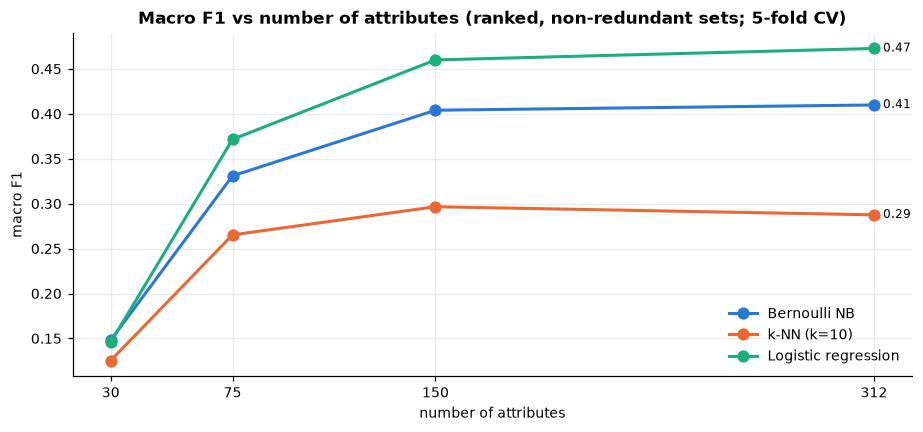

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4))
ranked = results[results["feature set"].str.startswith(("all", "ranked"))]
colours = dict(zip(models, [BLUE, ORANGE, AQUA]))
for model_name, colour in colours.items():
    r = ranked[ranked["model"] == model_name].sort_values("n")
    ax.plot(r["n"], r["f1"], marker="o", ms=7, lw=2, color=colour, label=model_name)
    ax.annotate(f'{r["f1"].iloc[-1]:.2f}', (r["n"].iloc[-1], r["f1"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8)
ax.set(title="Macro F1 vs number of attributes (ranked, non-redundant sets; 5-fold CV)",
       xlabel="number of attributes", ylabel="macro F1", xticks=[30, 75, 150, 312])
ax.legend(loc="lower right")
plt.tight_layout()
save_figure(fig, "features_evaluation")
plt.show()

In [10]:
# Full metric table for the best model, as asked in the Model Testing lab
best_model = f1_table.drop(columns="n").mean().idxmax()
(results[results["model"] == best_model]
    .set_index("feature set")[["n", "accuracy", "precision", "recall", "f1"]]
    .reindex(f1_table.index).round(3))

,n,accuracy,precision,recall,f1
feature set,,,,,
all 312,312,0.478,0.499,0.478,0.473
per-class top 2,162,0.438,0.452,0.438,0.427
per-class top 5,244,0.474,0.492,0.474,0.467
per-class top 10,288,0.483,0.507,0.483,0.479
ranked top 150,150,0.469,0.482,0.469,0.460
ranked top 75,75,0.389,0.389,0.389,0.372
ranked top 30,30,0.180,0.160,0.180,0.146
PCA 75 components,75,0.434,0.445,0.434,0.425


**Findings** (numbers in the tables above):

* **About half of the attributes carry most of the information.** The ranked top-150 set loses only about 1 point of
  macro F1 compared with all 312 (logistic regression 0.460 vs 0.473), and the lab's per-class top-10 set
  (288 attributes) is as good as using everything.
* **Below that, performance falls quickly**: 75 attributes cost about 10 points, and 30 attributes collapse to
  ~0.14 macro F1. With 200 look-alike species, fine distinctions need many attributes — a property of the
  fine-grained problem, not a failure of the ranking.
* **k-NN behaves differently:** it gets slightly *better* with fewer attributes (0.297 with 150 vs 0.283 with 312),
  because irrelevant attributes add noise to every distance (Lecture 3: k-NN treats all features as equally important).
* **Logistic regression is best at every size**, Bernoulli Naïve Bayes second, k-NN last.
* **Feature extraction vs selection:** PCA with 75 components keeps more information than the 75 selected attributes
  (0.425 vs 0.372 for logistic regression) because each component mixes many attributes — but the components can no
  longer be read as "red crown" or "hooked bill", so interpretability is lost.

**Recommendation for R3:** use **all 312** attributes as the main input, and the **ranked top 150 / 75 / 30** sets as the
lab's "Data set 1/2/3" for feature-size experiments.

## 7. Saving the feature sets

In [11]:
to_save = {
    "description": "Feature sets for CUB-200-2011 attributes (variant A), built on the official TRAINING split only (featureSelection.ipynb).",
    "ranking_cramers_v": list(ranking.index),
    "redundancy_threshold": REDUNDANCY_THRESHOLD,
    "sets": {name: cols for name, cols in feature_sets.items()},
}
path = DATA / "feature_sets.json"
path.write_text(json.dumps(to_save, indent=2))
print(f"Saved {len(feature_sets)} feature sets to {path.relative_to(ROOT)}")

# How a teammate uses it in R3:
#   sets = json.load(open(DATA / "feature_sets.json"))["sets"]
#   X_train = train[sets["ranked top 75"]]

Saved 7 feature sets to data\feature_sets.json
